# Fixed-design PPO analysis

This notebook checks whether the PPO controller learns when PV and battery capacities remain fixed. It focuses on cost convergence, PPO diagnostics, action saturation and actor parameter changes.

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from train_rl import CoDesignTrainer, DEFAULT_YEAR, generate_dataset

RUN_DIRECTORY = Path("runs/ppo_fixed_6.6_4.5")
ROLLING_WINDOW = 25
COMPARISON_EPISODES = 64

In [4]:
required = ["training.csv", "training_samples.csv", "validation.json", "configuration.json", "checkpoint.pt"]
missing = [name for name in required if not (RUN_DIRECTORY / name).exists()]
if missing:
    raise FileNotFoundError(f"Missing files in {RUN_DIRECTORY}: {missing}")

history = pd.read_csv(RUN_DIRECTORY / "training.csv")
samples = pd.read_csv(RUN_DIRECTORY / "training_samples.csv")
with (RUN_DIRECTORY / "validation.json").open() as file:
    validation = json.load(file)
with (RUN_DIRECTORY / "configuration.json").open() as file:
    configuration = json.load(file)
checkpoint = torch.load(RUN_DIRECTORY / "checkpoint.pt", map_location="cpu", weights_only=True)

## Run summary

In [5]:
fixed_design = configuration["rl"]["training"]["fixed_design_values"]
designs = samples[["pv_capacity_kwp", "battery_capacity_kwh"]].drop_duplicates()
if len(designs) != 1:
    raise ValueError(f"Expected one fixed design, found {len(designs)}")

pd.Series({
    "iterations": len(history),
    "episodes per iteration": configuration["rl"]["training"]["episodes_per_iteration"],
    "seed": configuration["rl"]["seed"],
    "PV capacity (kWp)": fixed_design[0],
    "battery capacity (kWh)": fixed_design[1],
    "final validation episodes": validation["episodes"],
    "final validation cost (CHF)": validation["mean_cost_chf"],
    "final validation cost std (CHF)": validation["std_reward_chf"],
}, name="value").to_frame()

,value
iterations,500.000000
episodes per iteration,32.000000
seed,42.000000
PV capacity (kWp),6.600000
battery capacity (kWh),4.500000
final validation episodes,320.000000
final validation cost (CHF),89.396216
final validation cost std (CHF),7.182324


## Cost convergence

Faint lines show the raw values and solid lines show a centred rolling mean.

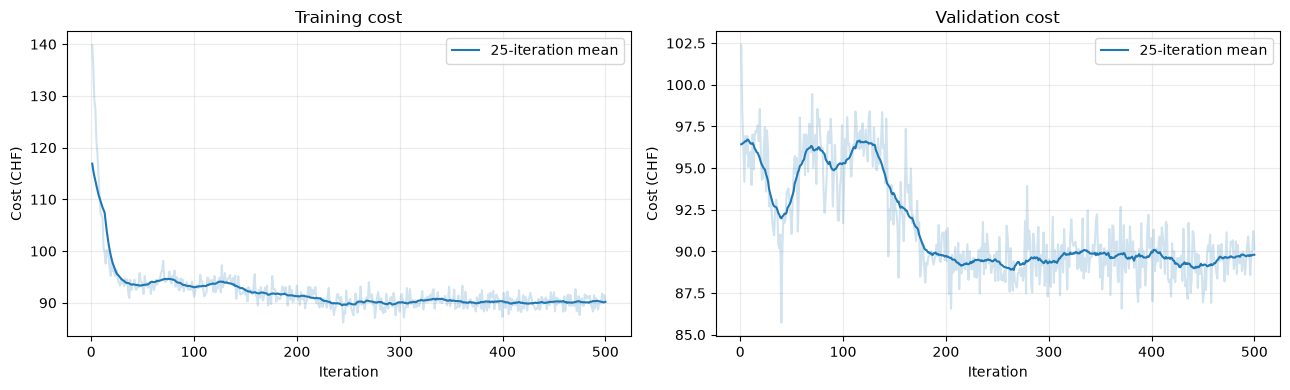

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
curves = [
    ("mean_cost_chf", "Training cost"),
    ("validation_mean_cost_chf", "Validation cost"),
]
for axis, (column, title) in zip(axes, curves):
    rolling = history[column].rolling(ROLLING_WINDOW, center=True, min_periods=1).mean()
    axis.plot(history["iteration"], history[column], alpha=0.2, color="tab:blue")
    axis.plot(history["iteration"], rolling, color="tab:blue", label=f"{ROLLING_WINDOW}-iteration mean")
    axis.set(title=title, xlabel="Iteration", ylabel="Cost (CHF)")
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()

## PPO and control diagnostics

Policy loss close to zero is not sufficient evidence of failed learning. Entropy and action saturation show how the controller's behaviour changes during training.

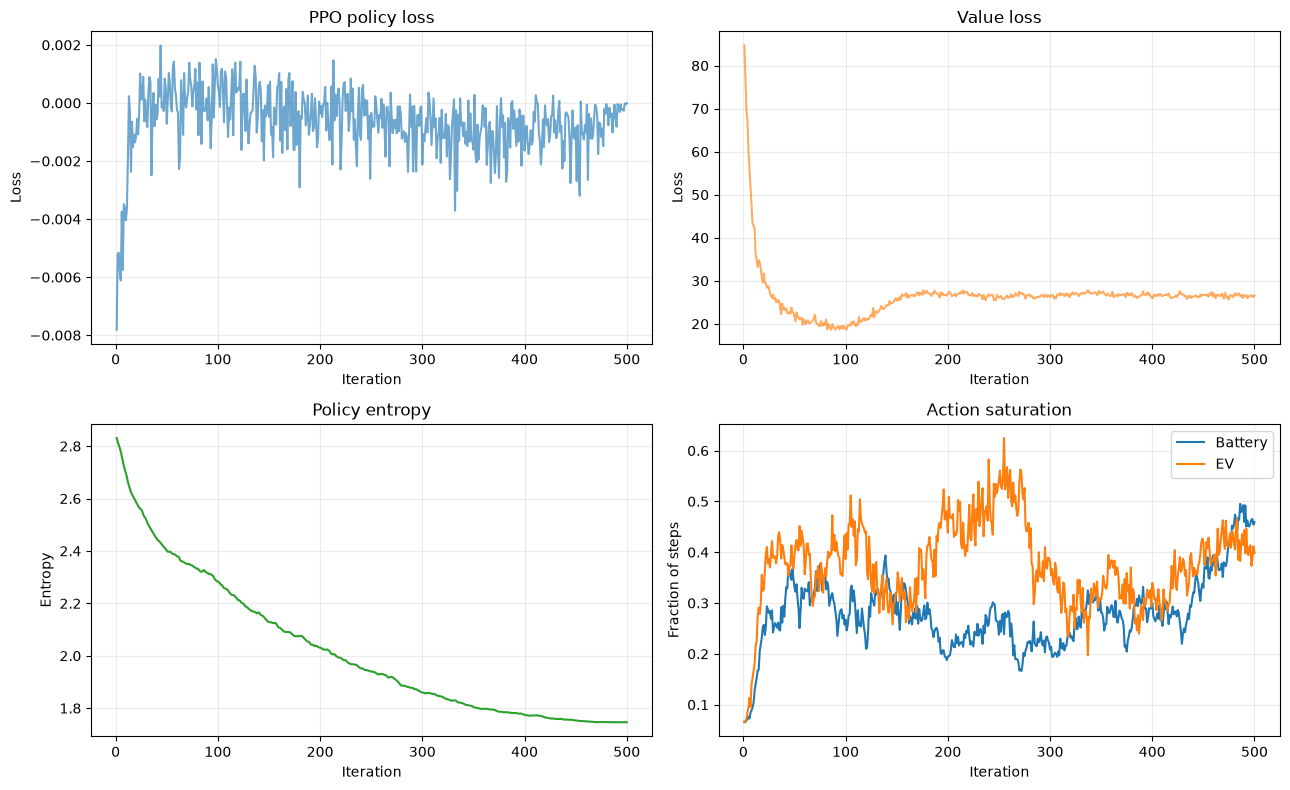

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(history["iteration"], history["policy_loss"], alpha=0.65)
axes[0, 0].set(title="PPO policy loss", ylabel="Loss")
axes[0, 1].plot(history["iteration"], history["value_loss"], alpha=0.65, color="tab:orange")
axes[0, 1].set(title="Value loss", ylabel="Loss")
axes[1, 0].plot(history["iteration"], history["action_entropy"], color="tab:green")
axes[1, 0].set(title="Policy entropy", ylabel="Entropy")
axes[1, 1].plot(history["iteration"], history["battery_action_saturation"], label="Battery")
axes[1, 1].plot(history["iteration"], history["ev_action_saturation"], label="EV")
axes[1, 1].set(title="Action saturation", ylabel="Fraction of steps")
axes[1, 1].legend()
for axis in axes.flat:
    axis.set_xlabel("Iteration")
    axis.grid(alpha=0.25)
plt.tight_layout()

## Actor parameter changes

The final checkpoint is compared with a freshly initialised PPO network using the same seed and configuration.

In [8]:
data = generate_dataset(
    year=DEFAULT_YEAR,
    days=configuration["rl"]["training"]["dataset_days"],
    seed=configuration["rl"]["training"].get("dataset_seed", configuration["rl"]["seed"]),
)
initial_trainer = CoDesignTrainer(
    configuration["system"], data, configuration["rl"], seed=configuration["rl"]["seed"]
)
final_trainer = CoDesignTrainer(
    configuration["system"], data, configuration["rl"], seed=configuration["rl"]["seed"]
)
final_trainer.agent.network.load_state_dict(checkpoint["agent"]["network"])

initial_state = initial_trainer.agent.network.state_dict()
final_state = final_trainer.agent.network.state_dict()
rows = []
for name in initial_state:
    if name.startswith("actor.") or name == "log_std":
        delta = final_state[name] - initial_state[name]
        rows.append({
            "parameter": name,
            "parameters": delta.numel(),
            "changed": int((delta != 0).sum()),
            "delta_l2": float(delta.norm()),
        })
actor_changes = pd.DataFrame(rows)
actor_changes

,parameter,parameters,changed,delta_l2
0,log_std,2,2,0.781658
1,actor.0.weight,1408,1280,1.335286
2,actor.0.bias,128,128,0.366544
3,actor.2.weight,16384,16384,2.696358
4,actor.2.bias,128,128,0.072394
5,actor.4.weight,16384,16384,2.021813
6,actor.4.bias,128,128,0.131811
7,actor.6.weight,256,256,0.271752
8,actor.6.bias,2,2,0.016731


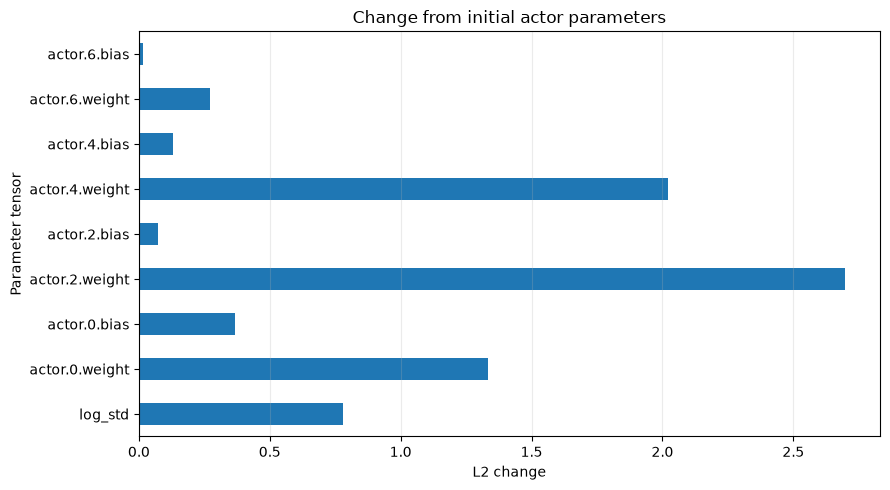

In [9]:
axis = actor_changes.plot.barh(x="parameter", y="delta_l2", figsize=(9, 5), legend=False)
axis.set(title="Change from initial actor parameters", xlabel="L2 change", ylabel="Parameter tensor")
axis.grid(axis="x", alpha=0.25)
plt.tight_layout()

## Matched initial and trained controller comparison

Both deterministic controllers are evaluated on the same stochastic scenario seeds with the same fixed design.

In [10]:
iteration = checkpoint["completed_iterations"]
design = np.asarray(fixed_design, dtype=np.float32)
matched_costs = {}
for label, trainer in {"Initial actor": initial_trainer, "Trained actor": final_trainer}.items():
    trainer.completed_iterations = iteration
    matched_costs[label] = [
        trainer._run_episode(
            design=design,
            split="validation",
            seed=trainer._episode_seed(iteration, episode, "validation"),
            training=False,
            stochastic_policy=False,
        )["cost_chf"]
        for episode in range(COMPARISON_EPISODES)
    ]
matched_costs = pd.DataFrame(matched_costs)
matched_costs.describe().loc[["mean", "std", "min", "max"]]

,Initial actor,Trained actor
mean,106.216435,89.890947
std,10.127715,7.063911
min,93.238112,77.111349
max,123.962937,106.948949


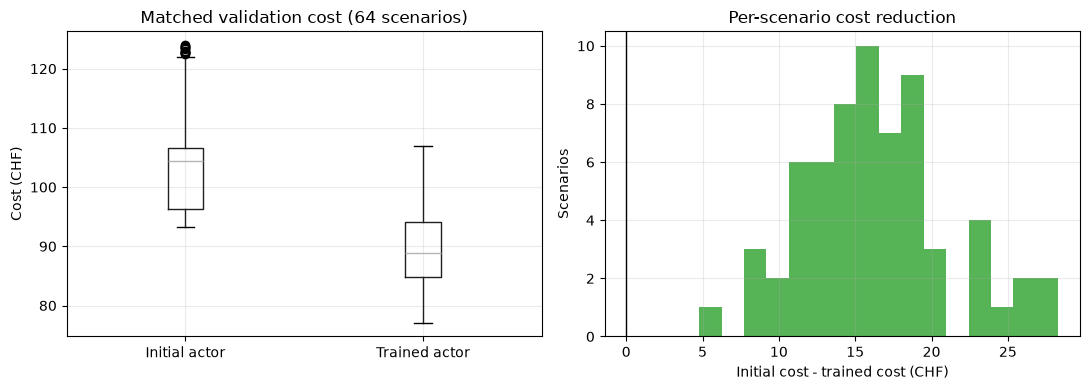

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
matched_costs.boxplot(ax=axes[0])
axes[0].set(title=f"Matched validation cost ({COMPARISON_EPISODES} scenarios)", ylabel="Cost (CHF)")
difference = matched_costs["Initial actor"] - matched_costs["Trained actor"]
axes[1].hist(difference, bins=16, color="tab:green", alpha=0.8)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(title="Per-scenario cost reduction", xlabel="Initial cost - trained cost (CHF)", ylabel="Scenarios")
for axis in axes:
    axis.grid(alpha=0.25)
plt.tight_layout()

## Five-seed checkpoint analysis

Seeds 42--46 use the same dataset and fixed design. The shared checkpoint is selected from the mean smoothed validation curve, then compared with iteration 500 on 320 common test scenarios that were not used for checkpoint selection.

In [12]:
MULTI_SEED_ROOT = Path("runs/ppo_fixed_6.6_4.5_multiseed")
seed_directories = sorted(path for path in MULTI_SEED_ROOT.glob("seed_*") if path.is_dir())
if len(seed_directories) != 5:
    raise FileNotFoundError(f"Expected five seed runs in {MULTI_SEED_ROOT}")

histories = []
for directory in seed_directories:
    seed = int(directory.name.split("_")[-1])
    frame = pd.read_csv(directory / "training.csv")
    frame["seed"] = seed
    frame["training_smoothed"] = frame["mean_cost_chf"].rolling(ROLLING_WINDOW, center=True, min_periods=ROLLING_WINDOW).mean()
    frame["validation_smoothed"] = frame["validation_mean_cost_chf"].rolling(ROLLING_WINDOW, center=True, min_periods=ROLLING_WINDOW).mean()
    histories.append(frame)
multi_history = pd.concat(histories, ignore_index=True)
aggregate = multi_history.groupby("iteration").agg(
    training_mean=("training_smoothed", "mean"),
    training_std=("training_smoothed", "std"),
    validation_mean=("validation_smoothed", "mean"),
    validation_std=("validation_smoothed", "std"),
).reset_index()
best_iteration = int(aggregate.loc[aggregate["validation_mean"].idxmin(), "iteration"])
checkpoint_iterations = sorted(int(path.stem.split("_")[-1]) for path in (seed_directories[0] / "checkpoints").glob("*.pt"))
selected_iteration = min(checkpoint_iterations, key=lambda value: abs(value - best_iteration))
selected_iteration

430

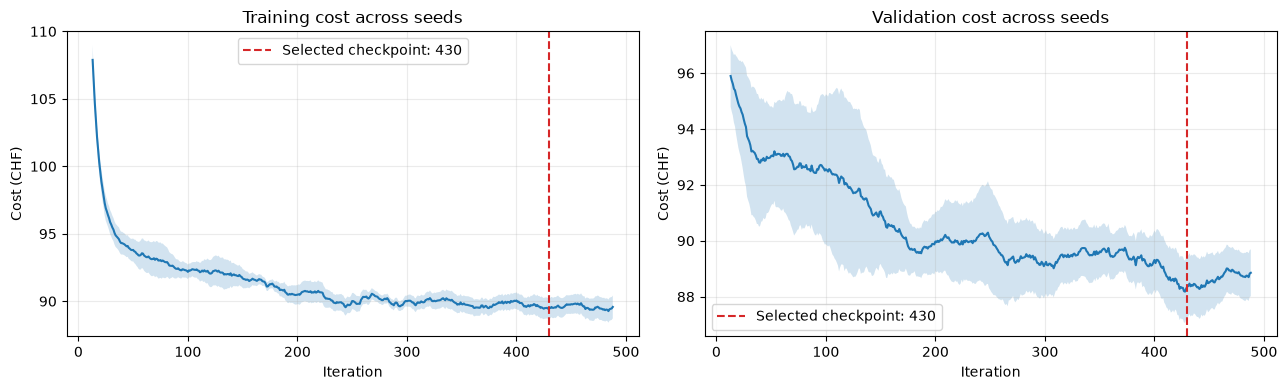

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for axis, mean_column, std_column, title in [
    (axes[0], "training_mean", "training_std", "Training cost across seeds"),
    (axes[1], "validation_mean", "validation_std", "Validation cost across seeds"),
]:
    axis.plot(aggregate["iteration"], aggregate[mean_column], color="tab:blue")
    axis.fill_between(aggregate["iteration"], aggregate[mean_column] - aggregate[std_column], aggregate[mean_column] + aggregate[std_column], alpha=0.2)
    axis.axvline(selected_iteration, color="tab:red", linestyle="--", label=f"Selected checkpoint: {selected_iteration}")
    axis.set(title=title, xlabel="Iteration", ylabel="Cost (CHF)")
    axis.grid(alpha=0.25)
    axis.legend()
plt.tight_layout()

In [14]:
checkpoint_tests = pd.concat(
    [pd.read_csv(directory / "checkpoint_test.csv") for directory in seed_directories],
    ignore_index=True,
)
checkpoint_summary = checkpoint_tests.groupby(["training_seed", "iteration"])["cost_chf"].mean().unstack()
checkpoint_summary["500 minus selected"] = checkpoint_summary[500] - checkpoint_summary[selected_iteration]
checkpoint_summary

iteration,430,500,500 minus selected
training_seed,,,
42,89.910405,90.077099,0.166694
43,87.928494,88.666564,0.738071
44,88.679263,88.724565,0.045302
45,87.702756,88.332385,0.629629
46,90.213168,89.947187,-0.265982


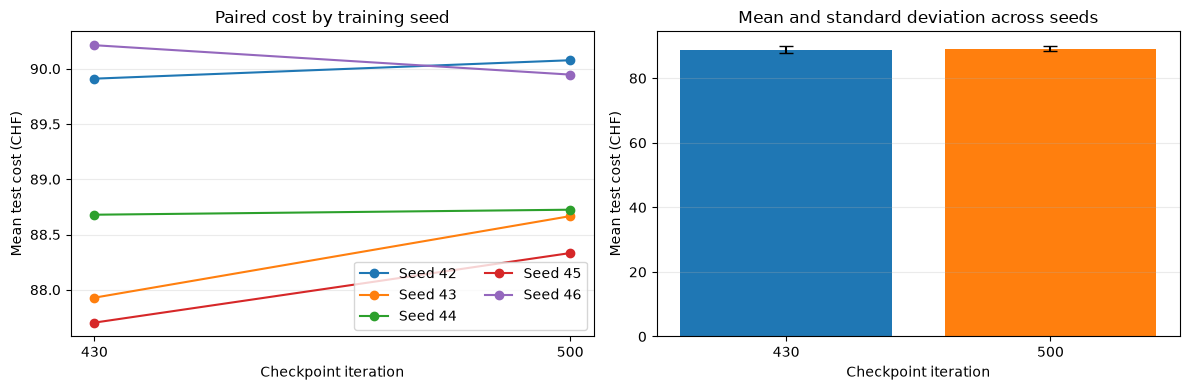

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed, row in checkpoint_summary.iterrows():
    axes[0].plot([selected_iteration, 500], [row[selected_iteration], row[500]], marker="o", label=f"Seed {seed}")
axes[0].set(title="Paired cost by training seed", xlabel="Checkpoint iteration", ylabel="Mean test cost (CHF)", xticks=[selected_iteration, 500])
axes[0].legend(ncol=2)
means = checkpoint_summary[[selected_iteration, 500]].mean()
errors = checkpoint_summary[[selected_iteration, 500]].std()
axes[1].bar([str(selected_iteration), "500"], means, yerr=errors, capsize=5, color=["tab:blue", "tab:orange"])
axes[1].set(title="Mean and standard deviation across seeds", xlabel="Checkpoint iteration", ylabel="Mean test cost (CHF)")
for axis in axes:
    axis.grid(axis="y", alpha=0.25)
plt.tight_layout()

In [16]:
difference = checkpoint_summary["500 minus selected"]
half_width = 2.776 * difference.std() / np.sqrt(len(difference))
pd.Series({
    "selected checkpoint": selected_iteration,
    "selected mean cost (CHF)": checkpoint_summary[selected_iteration].mean(),
    "iteration 500 mean cost (CHF)": checkpoint_summary[500].mean(),
    "500 minus selected cost (CHF)": difference.mean(),
    "difference 95% CI lower (CHF)": difference.mean() - half_width,
    "difference 95% CI upper (CHF)": difference.mean() + half_width,
    "seeds where selected is better": int((difference > 0).sum()),
}, name="value").to_frame()

,value
selected checkpoint,430.000000
selected mean cost (CHF),88.886817
iteration 500 mean cost (CHF),89.149560
500 minus selected cost (CHF),0.262743
difference 95% CI lower (CHF),-0.255336
difference 95% CI upper (CHF),0.780821
seeds where selected is better,4.000000


## Fixed-design sensitivity sweep

Four additional designs use seeds 42--44 with the same dataset and PPO settings. Validation runs every 10 iterations because it does not affect policy updates. The convergence diagnostic below is descriptive rather than paper-derived: the final 100-iteration mean must be within 0.25 CHF of the preceding 100 iterations and its absolute slope must be below 0.01 CHF per iteration.

In [17]:
SWEEP_ROOT = Path("runs/fixed_design_sweep")
sweep_designs = {
    "PV 4.0, battery 4.5": "pv4_battery4p5",
    "PV 9.0, battery 4.5": "pv9_battery4p5",
    "PV 6.6, battery 2.0": "pv6p6_battery2",
    "PV 6.6, battery 8.0": "pv6p6_battery8",
}
sweep_histories = []
sweep_final = []
for design_label, directory_name in sweep_designs.items():
    for seed in (42, 43, 44):
        directory = SWEEP_ROOT / directory_name / f"seed_{seed}"
        frame = pd.read_csv(directory / "training.csv")
        frame["design"] = design_label
        frame["seed"] = seed
        frame["training_smoothed"] = frame["mean_cost_chf"].rolling(25, center=True, min_periods=25).mean()
        sweep_histories.append(frame)
        with (directory / "validation.json").open() as file:
            result = json.load(file)
        sweep_final.append({"design": design_label, "seed": seed, "cost_chf": result["mean_cost_chf"]})
sweep_history = pd.concat(sweep_histories, ignore_index=True)
sweep_final = pd.DataFrame(sweep_final)

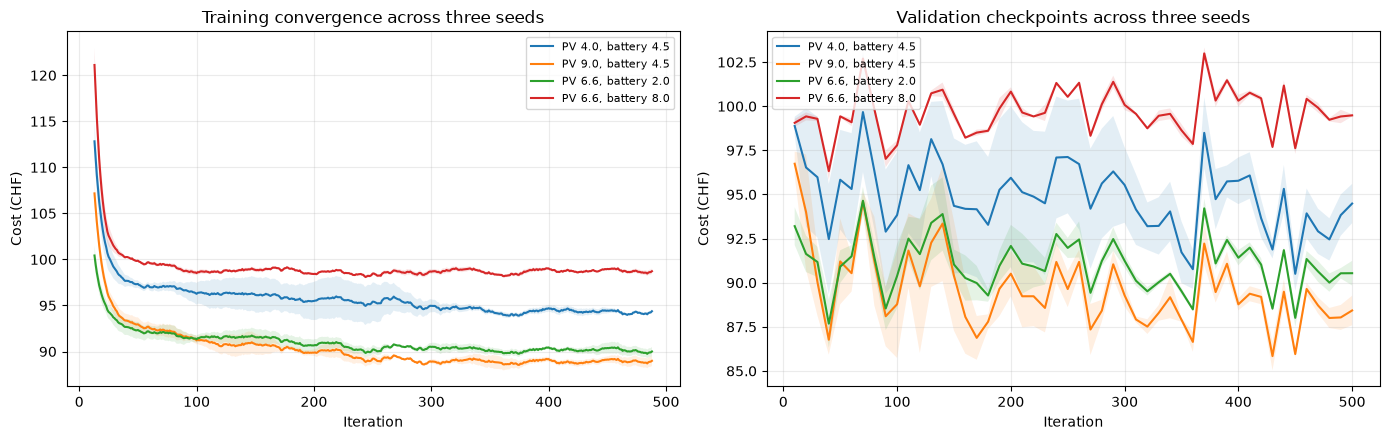

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for design_label in sweep_designs:
    selected = sweep_history[sweep_history["design"] == design_label]
    training_curve = selected.groupby("iteration")["training_smoothed"].agg(["mean", "std"])
    validation_curve = selected.dropna(subset=["validation_mean_cost_chf"]).groupby("iteration")["validation_mean_cost_chf"].agg(["mean", "std"])
    axes[0].plot(training_curve.index, training_curve["mean"], label=design_label)
    axes[0].fill_between(training_curve.index, training_curve["mean"] - training_curve["std"], training_curve["mean"] + training_curve["std"], alpha=0.12)
    axes[1].plot(validation_curve.index, validation_curve["mean"], label=design_label)
    axes[1].fill_between(validation_curve.index, validation_curve["mean"] - validation_curve["std"], validation_curve["mean"] + validation_curve["std"], alpha=0.12)
axes[0].set(title="Training convergence across three seeds", xlabel="Iteration", ylabel="Cost (CHF)")
axes[1].set(title="Validation checkpoints across three seeds", xlabel="Iteration", ylabel="Cost (CHF)")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
plt.tight_layout()

In [ ]:
convergence_rows = []
for design_label in sweep_designs:
    aggregate_design = sweep_history[sweep_history["design"] == design_label].groupby("iteration")["mean_cost_chf"].mean().reset_index()
    previous = aggregate_design[aggregate_design["iteration"].between(301, 400)]["mean_cost_chf"].mean()
    late = aggregate_design[aggregate_design["iteration"].between(401, 500)]
    slope = np.polyfit(late["iteration"], late["mean_cost_chf"], 1)[0]
    change = late["mean_cost_chf"].mean() - previous
    final_costs = sweep_final[sweep_final["design"] == design_label]["cost_chf"]
    convergence_rows.append({
        "design": design_label,
        "final cost mean (CHF)": final_costs.mean(),
        "final cost seed std (CHF)": final_costs.std(),
        "late-window change (CHF)": change,
        "late slope (CHF/iteration)": slope,
        "converged by diagnostic": abs(change) < 0.25 and abs(slope) < 0.01,
    })
convergence = pd.DataFrame(convergence_rows).set_index("design").sort_values("final cost mean (CHF)")
convergence

In [ ]:
axis = convergence["final cost mean (CHF)"].plot.bar(
    yerr=convergence["final cost seed std (CHF)"], figsize=(10, 4.5), capsize=4
)
axis.set(title="Final fixed-design cost across seeds 42--44", xlabel="", ylabel="Mean cost (CHF)")
axis.grid(axis="y", alpha=0.25)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()